# Oversampling

## Previous work 
As the visualization of the data `data/EstrogenReceptorStatus_Test.csv` had shown there is a clear class imbalance, this means that the number of instances for one class is larger in nearlya 3:1 proportion, because of that wea are mading an oversampling aproximation in order to try correct this imbalance in the dataset 

## Oversampling step
For this procedure of the processing we tested the implementations of the imbalanced learn library, specifically the SMOTE in it 3 different modes and ADASYN.

In [4]:
#set up 
import os
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
import seaborn as sns
from adjustText import adjust_text
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import ADASYN, BorderlineSMOTE, KMeansSMOTE, SVMSMOTE
from imblearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid
import matplotlib.pyplot as plt

Oversampling needs to be maded at train level in order to do not make data leakage and bias the results of the training in a optimistic way, for that the k-fold cross validation is maded different compared with the traditional `GridSearchCV` function, in the same sense it is important to note that this has to be maded while the crossvalidation is been mading with the particularity that, in order to do no have data leakeage, only in the trains folds and no in the validation ones, beacuse this can introduce samples or informatio of those that the model have not seen.

In [ ]:
#functions
def train_M(model_ML:str, X_train:np.arange, y_train:np.arange, hiper_P:dict=None, k:int=5, name:str="ML_train", over_samp:dict=None, rd:int=42):
    """
    Function that trains 3 different machine learning algorthms 
    Arguments:
        -model_ML: type of model to create, 3 suported options: DT for desicion trees 
            RF for random forest and SVM for suported vector machines 
        -X_train: set of all the variables to be used for training
        -y_train: labels of the variable of interest to be predicted in the X_train 
        -hiper_P: dictionary with the hiperparameter names as keys and a list for the values for 
            the grid for each hiperparameter 
        -name: name to be used in the res df
        -over_samp: dictionary with key as the type of oversampling method (over map s function dic supported values)
        -rd: random state for the run 
    """
    #diccionario para mapear los metodos de oversampling con su funcion 
    over_map={
        "adasyn":[ADASYN(random_state=rd)],
        "k_means":[KMeansSMOTE(random_state=rd)],
        "borderline":[BorderlineSMOTE(random_state=rd)],
        "SVM":[SVMSMOTE(random_state=rd)]
    }
    model_ML_map = {
        "DT": tree.DecisionTreeClassifier(random_state=rd),
        "RF": RandomForestClassifier(random_state=rd),
        "SVM": SVC(random_state=rd),
    }
    #inicializamos los objetos si se va a hacer over samplig o no 
    if over_samp:
        #grid de hiper parametros
        param_grid=[{
                "Osampler":over_map[o_sampler],
                **{f"Osampler__{over_hp}": hp_v for over_hp, hp_v in over_samp[o_sampler].items()},
                **{f"model__{model_hp}": hp_v for model_hp, hp_v in hiper_P.items()}
            } for o_sampler in over_samp.keys()
        ]
        #inicializamos el objeto pipeline 
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("Osampler", BorderlineSMOTE(random_state=rd)),
            ("model",model_ML_map[model_ML]),
        ])
    else:
        #grid the hiper parametros
        param_grid={f"model__{model_hp}": hp_v for model_hp, hp_v in hiper_P.items()}
        #inicializamos el objeto pipeline solo con el clasificador
        pipe = Pipeline([
            ("model",model_ML_map[model_ML])
        ])
    #configurar el k-fold cross validation 
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=rd)
    #hacer el grid de hiperparametros 
    models_grid= GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
    )
    grid_df=pd.DataFrame(ParameterGrid(models_grid.param_grid))
    #entrenar el modelo
    print(grid_df)

#parsing the hiper parameters
def parse_hp(hp_str:str):
    """
    Function that parses the hiperparameters of a machine learning model
    """
    dic_hp={"HP":
        {hip.strip().split(":")[0]:[hip_val.strip() 
                for hip_val in hip.strip().split(":")[1].strip().split(",")] 
            for hip in hp_str.strip().split("|")
        }
    }
    return dic_hp

## Oversampling Methods

For the implementation in the `imbalanced-learn` package, the main algorithms that perform this task share common arguments while also having their own specific hyperparameters.

The two baseline implementations are **SMOTE** and **ADASYN**. The main difference between them is that SMOTE takes into account both inner and outer samples to perform oversampling, providing a broader representation of the variance across the dataset. In contrast, ADASYN focuses mainly on outer samples (those located closer to instances of other classes) to fill the information gap of the underrepresented class in the most problematic regions. Both methods compute linear interpolation between neighbors of the same class, differing in how they select which samples will generate synthetic points:
$$
x_{new} = x_i + \lambda(x_{neighbor} - x_i)
$$

It is important to note that specialized SMOTE variants such as **BorderlineSMOTE**, **KMeansSMOTE**, and **SVMSMOTE** can exhibit behavior similar to ADASYN by concentrating synthetic sample generation on specific regions or decision boundaries.

### Shared hyperparameters
The most common parameter in oversampling is `sampling_strategy`, which controls how the resampling will be performed to address the class imbalance:

`sampling_strategy` (default: `'auto'`):
- `'auto'`: Oversamples all minority classes to match the majority class size.
- `'minority'`: Oversamples only the minority class.
- `'not minority'`: Oversamples all classes except the minority one.
- `'not majority'`: Oversamples all classes except the majority one.
- `'all'`: Performs oversampling across all classes.
- `float`: Sets the desired ratio of the minority class over the majority class ($\alpha = N_{\text{min}} / N_{\text{maj}}$, binary classification only).
- `dict`: Specifies in a dictionary the exact final number of samples for each class.

`random_state` (default: `None`):
- `int`, `RandomState` instance, or `None`: Controls the seed of the pseudo-random number generator to ensure reproducible neighbor selection and interpolation steps.

### Particular hyperparameters

#### 1. SMOTE
`k_neighbors` (default: `5`):
- `int` or `NearestNeighbors` object: Number of nearest neighbors **from the same minority class** used to construct synthetic samples via linear interpolation. Lower values keep synthetic points closer to original samples, while higher values increase sample diversity.

#### 2. ADASYN
`n_neighbors` (default: `5`):
- `int` or `NearestNeighbors` object: Number of nearest neighbors **across all classes** used to compute the local density ratio $r_i = \Delta_i / K$ (proportion of majority-class neighbors). Minority points surrounded by more majority instances generate proportionally more synthetic samples.

#### 3. BorderlineSMOTE
`k_neighbors` (default: `5`):
- `int` or `NearestNeighbors` object: Number of nearest minority neighbors used to perform interpolation.

`m_neighbors` (default: `10`):
- `int` or `NearestNeighbors` object: Number of nearest neighbors across all classes used to evaluate whether a minority sample is "in danger" (near the decision boundary).

`kind` (default: `'borderline-1'`):
- `'borderline-1'`: Generates synthetic samples by interpolating between a borderline minority sample and its nearest neighbors from the **same minority class**.
- `'borderline-2'`: Interpolates with nearest neighbors from **any class** (including the majority class, restricting $\lambda \in [0, 0.5]$ so new points stay closer to the minority instance).

#### 4. KMeansSMOTE
`cluster_balance_threshold` (default: `'auto'`):
- `float` or `'auto'`: Minimum ratio of minority to majority instances ($\frac{N_{\text{min}, c} + 1}{N_{\text{maj}, c} + 1}$) required for a cluster to be selected for oversampling.
  - Lower values (e.g., `0.05`): More permissive; allows oversampling in mixed boundary clusters but increases the risk of introducing noise.
  - Higher values (e.g., `0.15`): Stricter; filters out majority-dominated clusters for cleaner synthetic data, though it may raise an error if no clusters meet the threshold in heavily imbalanced datasets.

`kmeans_estimator` (default: `None`):
- `int` or `KMeans` object: Number of clusters to partition the dataset (defaults to `MiniBatchKMeans` with 100 clusters) or a custom `KMeans` estimator.

`k_neighbors` (default: `2`):
- `int` or `NearestNeighbors` object: Number of nearest minority neighbors used to generate synthetic samples inside each approved cluster.

`density_exponent` (default: `'auto'`):
- `float` or `'auto'`: Exponent used to weight cluster sparsity so that clusters with more dispersed minority samples receive proportionally more synthetic points.

#### 5. SVMSMOTE
`out_step` (default: `0.5`):
- `float` in `(0, 1]`: Maximum step size ($\rho$) used when extrapolating synthetic samples outward from minority support vectors toward the decision boundary ($x_{new} = x_i + \rho(x_i - x_{neighbor})$).
  - Lower values (e.g., `0.3`): Conservative extrapolation; safer when class boundaries are curved or noisy.
  - Higher values (e.g., `0.5`): Larger extrapolation steps; reinforces the decision margin more aggressively.

`svm_estimator` (default: `None`):
- `SVC` object: Custom Support Vector Classifier instance used to identify the minority-class support vectors along the decision boundary.

`k_neighbors` (default: `5`):
- `int` or `NearestNeighbors` object: Number of nearest minority neighbors used to determine the interpolation or extrapolation direction.

`m_neighbors` (default: `10`):
- `int` or `NearestNeighbors` object: Number of nearest neighbors across all classes evaluated around each support vector to decide whether to interpolate inward (when more than half are majority neighbors) or extrapolate outward (when fewer than half are majority neighbors).

In [10]:
#leer los datos 
cwd="/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state"
data_dic={
    "ANOVA":{
        "Train":pd.read_csv(os.path.join(cwd, "results/feature_selection", "anova_Train.csv"), index_col=0),
        "Test":pd.read_csv(os.path.join(cwd, "results/feature_selection", "anova_Test.csv"), index_col=0)
    },
    "MI":{
        "Train":pd.read_csv(os.path.join(cwd, "results/feature_selection", "mutual_information_Train.csv"), index_col=0),
        "Test":pd.read_csv(os.path.join(cwd, "results/feature_selection", "mutual_information_Test.csv"), index_col=0)
    },
    "Raw":{
        "Train":pd.read_csv(os.path.join(cwd, "data", "EstrogenReceptorStatus_Train.csv"), index_col=0),
        "Test":pd.read_csv(os.path.join(cwd, "data", "EstrogenReceptorStatus_Test.csv"), index_col=0)
    }
}

#get the labels 
test_labels = pd.read_csv(
    os.path.join(cwd, "data", "EstrogenReceptorStatus_Test_labels.txt"), header=None
)
train_labels = pd.read_csv(
    os.path.join(cwd, "data","EstrogenReceptorStatus_Train_labels.txt"), header=None
)
Labels=pd.concat([
    pd.merge(data_dic["Raw"]["Train"].reset_index(), 
            train_labels, left_index=True, right_index=True
    ),pd.merge(data_dic["Raw"]["Test"].reset_index(), 
            test_labels, left_index=True, right_index=True
    )
]).loc[:,["index",0]].set_index("index").rename_axis(None)


# mapper for the labels
lab_map = pd.Series(Labels.iloc[:, 0]) 
out_pth="/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test"

#completar los datasets para test 
for data_set in data_dic.keys():
    if data_set != "MT":
        for data_t  in data_dic[data_set].keys():
            #dim for dimensions 
            data_set_label=data_dic[data_set][data_t]
            print(f"Dimensionalidad data set{data_set}-{data_t}: {data_set_label.shape}")
            #assign the labels to the datasets
            data_set_label["group"]=data_set_label.index.map(lab_map)
            print(f"Dimensionalidad data set con labels{data_set}-{data_t}: {data_set_label.shape}")
            #save the files 
            data_set_label.to_csv(os.path.join(out_pth, f"{data_set}_{data_t}_with_labels_temp.csv"))

Dimensionalidad data setANOVA-Train: (216, 33)
Dimensionalidad data set con labelsANOVA-Train: (216, 34)
Dimensionalidad data setANOVA-Test: (55, 33)
Dimensionalidad data set con labelsANOVA-Test: (55, 34)
Dimensionalidad data setMI-Train: (216, 33)
Dimensionalidad data set con labelsMI-Train: (216, 34)
Dimensionalidad data setMI-Test: (55, 33)
Dimensionalidad data set con labelsMI-Test: (55, 34)
Dimensionalidad data setRaw-Train: (216, 162)
Dimensionalidad data set con labelsRaw-Train: (216, 163)
Dimensionalidad data setRaw-Test: (55, 162)
Dimensionalidad data set con labelsRaw-Test: (55, 163)


<positron-console-cell-10>:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-10>:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-10>:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-10>:46: PerformanceWarning: DataFrame is highly fragm

In [12]:
#Ml hiper paramters
dt_hp={"DT":parse_hp("criterion:gini,entropy|class_weight:balanced, None")}
rf_hp={"RF":parse_hp("class_weight:balanced , None| n_estimators:50,100,200,500 | criterion : gini ,  entropy")}
svm_hp={"SVM":parse_hp("kernel :linear |  C : 1,5,10")}
res_dic={ml_m : hp for dic in [dt_hp,rf_hp,svm_hp]  if dic for ml_m, hp in dic.items()}
print(res_dic)

#over samplinng hp 
smote_d="k_means^cluster_balance_threshold:0.05,0.15 | k_neighbors: 3, 5 ;borderline^ kind: borderline-1, borderline-2| k_neighbors: 3,5; SVM^ out_step: 0.3, 0.5 | k_neighbors: 3,5"
smote_d={ smote_t.strip().split("^")[0]: parse_hp(smote_t.strip().split("^")[1])["HP"]
    for smote_t in smote_d.strip().split(";")
} 

adasyn_d={"adasyn":parse_hp("n_neighbors: 3,5,7")["HP"]}
over_dic={over_m : hp for dic in [smote_d, adasyn_d]  if dic for over_m, hp in dic.items()} 
print(over_dic)

model_test="DT"

{'DT': {'HP': {'criterion': ['gini', 'entropy'], 'class_weight': ['balanced', 'None']}}, 'RF': {'HP': {'class_weight': ['balanced', 'None'], 'n_estimators': ['50', '100', '200', '500'], 'criterion ': ['gini', 'entropy']}}, 'SVM': {'HP': {'kernel ': ['linear'], 'C ': ['1', '5', '10']}}}
{'k_means': {'cluster_balance_threshold': ['0.05', '0.15'], 'k_neighbors': ['3', '5']}, 'borderline': {'kind': ['borderline-1', 'borderline-2'], 'k_neighbors': ['3', '5']}, 'SVM': {'out_step': ['0.3', '0.5'], 'k_neighbors': ['3', '5']}, 'adasyn': {'n_neighbors': ['3', '5', '7']}}


So the algorithm was implemented under the script `src/scripts/HC_ML_comparison.py` and with that it was run:

#### Anova Run

qsub -b y -N OverS_anov -o Over_s_anov.out -e Over_s_anov.err -cwd -q default -pe smp 6 -l h_vmem=50G \
conda run -p /export/space3/users/ismadlsh/conda/envs/data_science_R \
python /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/src/scripts/HC_ML_comparison.py \
-p OverS_all_ML_anova \
-d /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/ANOVA_Train_with_labels_temp.csv \
-a /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/ANOVA_Test_with_labels_temp.csv \
-o /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic \
-c group \
-x 'criterion:gini,entropy|class_weight:balanced,None' \
-f 'class_weight:balanced,None|n_estimators:50,100,200,500|criterion:gini,entropy' \
-v 'kernel:linear,rbf,poly|C:1,5,10' \
-i 'k_means^cluster_balance_threshold:0.05,0.15|k_neighbors:3,5;borderline^kind:borderline-1,borderline-2|k_neighbors:3,5;SVM^out_step:0.3,0.5|k_neighbors:3,5' \
-y 'n_neighbors:3,5,7' \
-j


#### Raw Run

qsub -b y -N OverS_raw -o Over_s_raw.out -e Over_s_raw.err -cwd -q default -pe smp 6 -l mem_free=100G \
conda run -p /export/space3/users/ismadlsh/conda/envs/data_science_R \
python /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/src/scripts/HC_ML_comparison.py \
-p OverS_all_ML \
-d /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/Raw_Train_with_labels_temp.csv \
-a /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/Raw_Test_with_labels_temp.csv \
-o /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic \
-c group \
-x 'criterion:gini,entropy|class_weight:balanced,None' \
-f 'class_weight:balanced,None|n_estimators:50,100,200,500|criterion:gini,entropy' \
-v 'kernel:linear,rbf,poly|C:1,5,10' \
-i 'k_means^cluster_balance_threshold:0.05,0.15|k_neighbors:3,5;borderline^kind:borderline-1,borderline-2|k_neighbors:3,5;SVM^out_step:0.3,0.5|k_neighbors:3,5' \
-y 'n_neighbors:3,5' \
-j 


### Withoout oversampling

#### Raw

qsub -b y -N MLc_raw -o MLc_raw.out -e MLc_raw.err -cwd -q default -pe smp 6 -l mem_free=100G \
conda run -p /export/space3/users/ismadlsh/conda/envs/data_science_R \
python /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/src/scripts/HC_ML_comparison.py \
-p MLc_all \
-d /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/Raw_Train_with_labels_temp.csv \
-a /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/Raw_Test_with_labels_temp.csv \
-o /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic \
-c group \
-x 'criterion:gini,entropy|class_weight:balanced,None' \
-f 'class_weight:balanced,None|n_estimators:50,100,200,500|criterion:gini,entropy' \
-v 'kernel:linear,rbf,poly|C:1,5,10' \
-j -s

#### Anova
qsub -b y -N MLc_anov -o MLc_anov.out -e MLc_anov.err -cwd -q default -pe smp 6 -l mem_free=100G \
conda run -p /export/space3/users/ismadlsh/conda/envs/data_science_R \
python /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/src/scripts/HC_ML_comparison.py \
-p MLc_all_anov \
-d /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/ANOVA_Train_with_labels_temp.csv \
-a /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/data/test/ANOVA_Test_with_labels_temp.csv \
-o /export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic \
-c group \
-x 'criterion:gini,entropy|class_weight:balanced,None' \
-f 'class_weight:balanced,None|n_estimators:50,100,200,500|criterion:gini,entropy' \
-v 'kernel:linear,rbf,poly|C:1,5,10' \
-j -s 

Thus the results are sumarized: 

In [6]:
res_dic={
    "Anova_over":pd.read_csv("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/OverS_all_ML_anova_final_compar_res.csv", index_col=0).set_index("Model").rename_axis(None),
    "Anova":pd.read_csv("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/MLc_all_anov_final_compar_res.csv", index_col=0).set_index("Model").rename_axis(None),
    "Raw_over":pd.read_csv("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/OverS_all_ML_final_compar_res.csv", index_col=0).set_index("Model").rename_axis(None),
    "Raw":pd.read_csv("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/MLc_all_final_compar_res.csv", index_col=0).set_index("Model").rename_axis(None)
}
res_df=pd.DataFrame()
#merge all the dataframes
for dic_t in res_dic.keys():
    #add the tags to the index
    res_dic[dic_t].index=dic_t +"_"+ res_dic[dic_t].index
    res_dic[dic_t]["hiperparameters"]=res_dic[dic_t]["hiperparameters"].str.replace("'", "")
    res_dic[dic_t]["hiperparameters"]=res_dic[dic_t]["hiperparameters"].str.replace("{", "")
    res_dic[dic_t]["hiperparameters"]=res_dic[dic_t]["hiperparameters"].str.replace("}", "")
    #concat with the res_df 
    res_df=pd.concat([res_df, res_dic[dic_t]])

res_df.to_csv("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/ML_classic_results_metrics.csv")
res_df.columns

Index(['hiperparameters', 'F-1_train_cv', 'F-1_score_macro', 'precision_macro',
       'recall_macro', 'AUROC_macro', 'F-1_score_weighted',
       'precision_weighted', 'recall_weighted'],
      dtype='str')

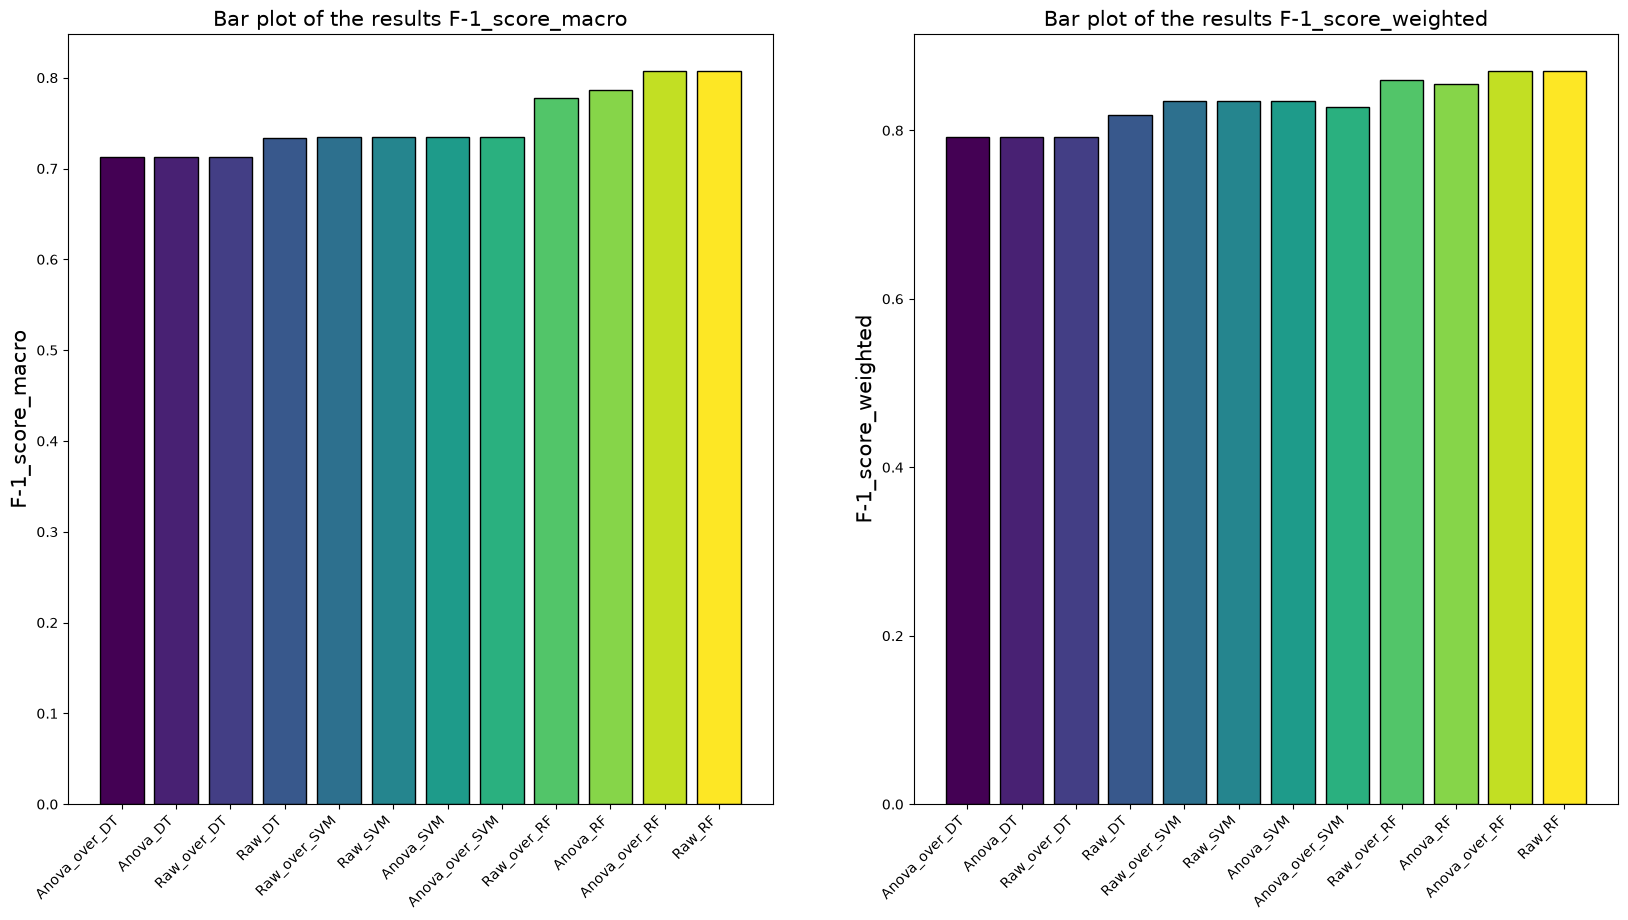

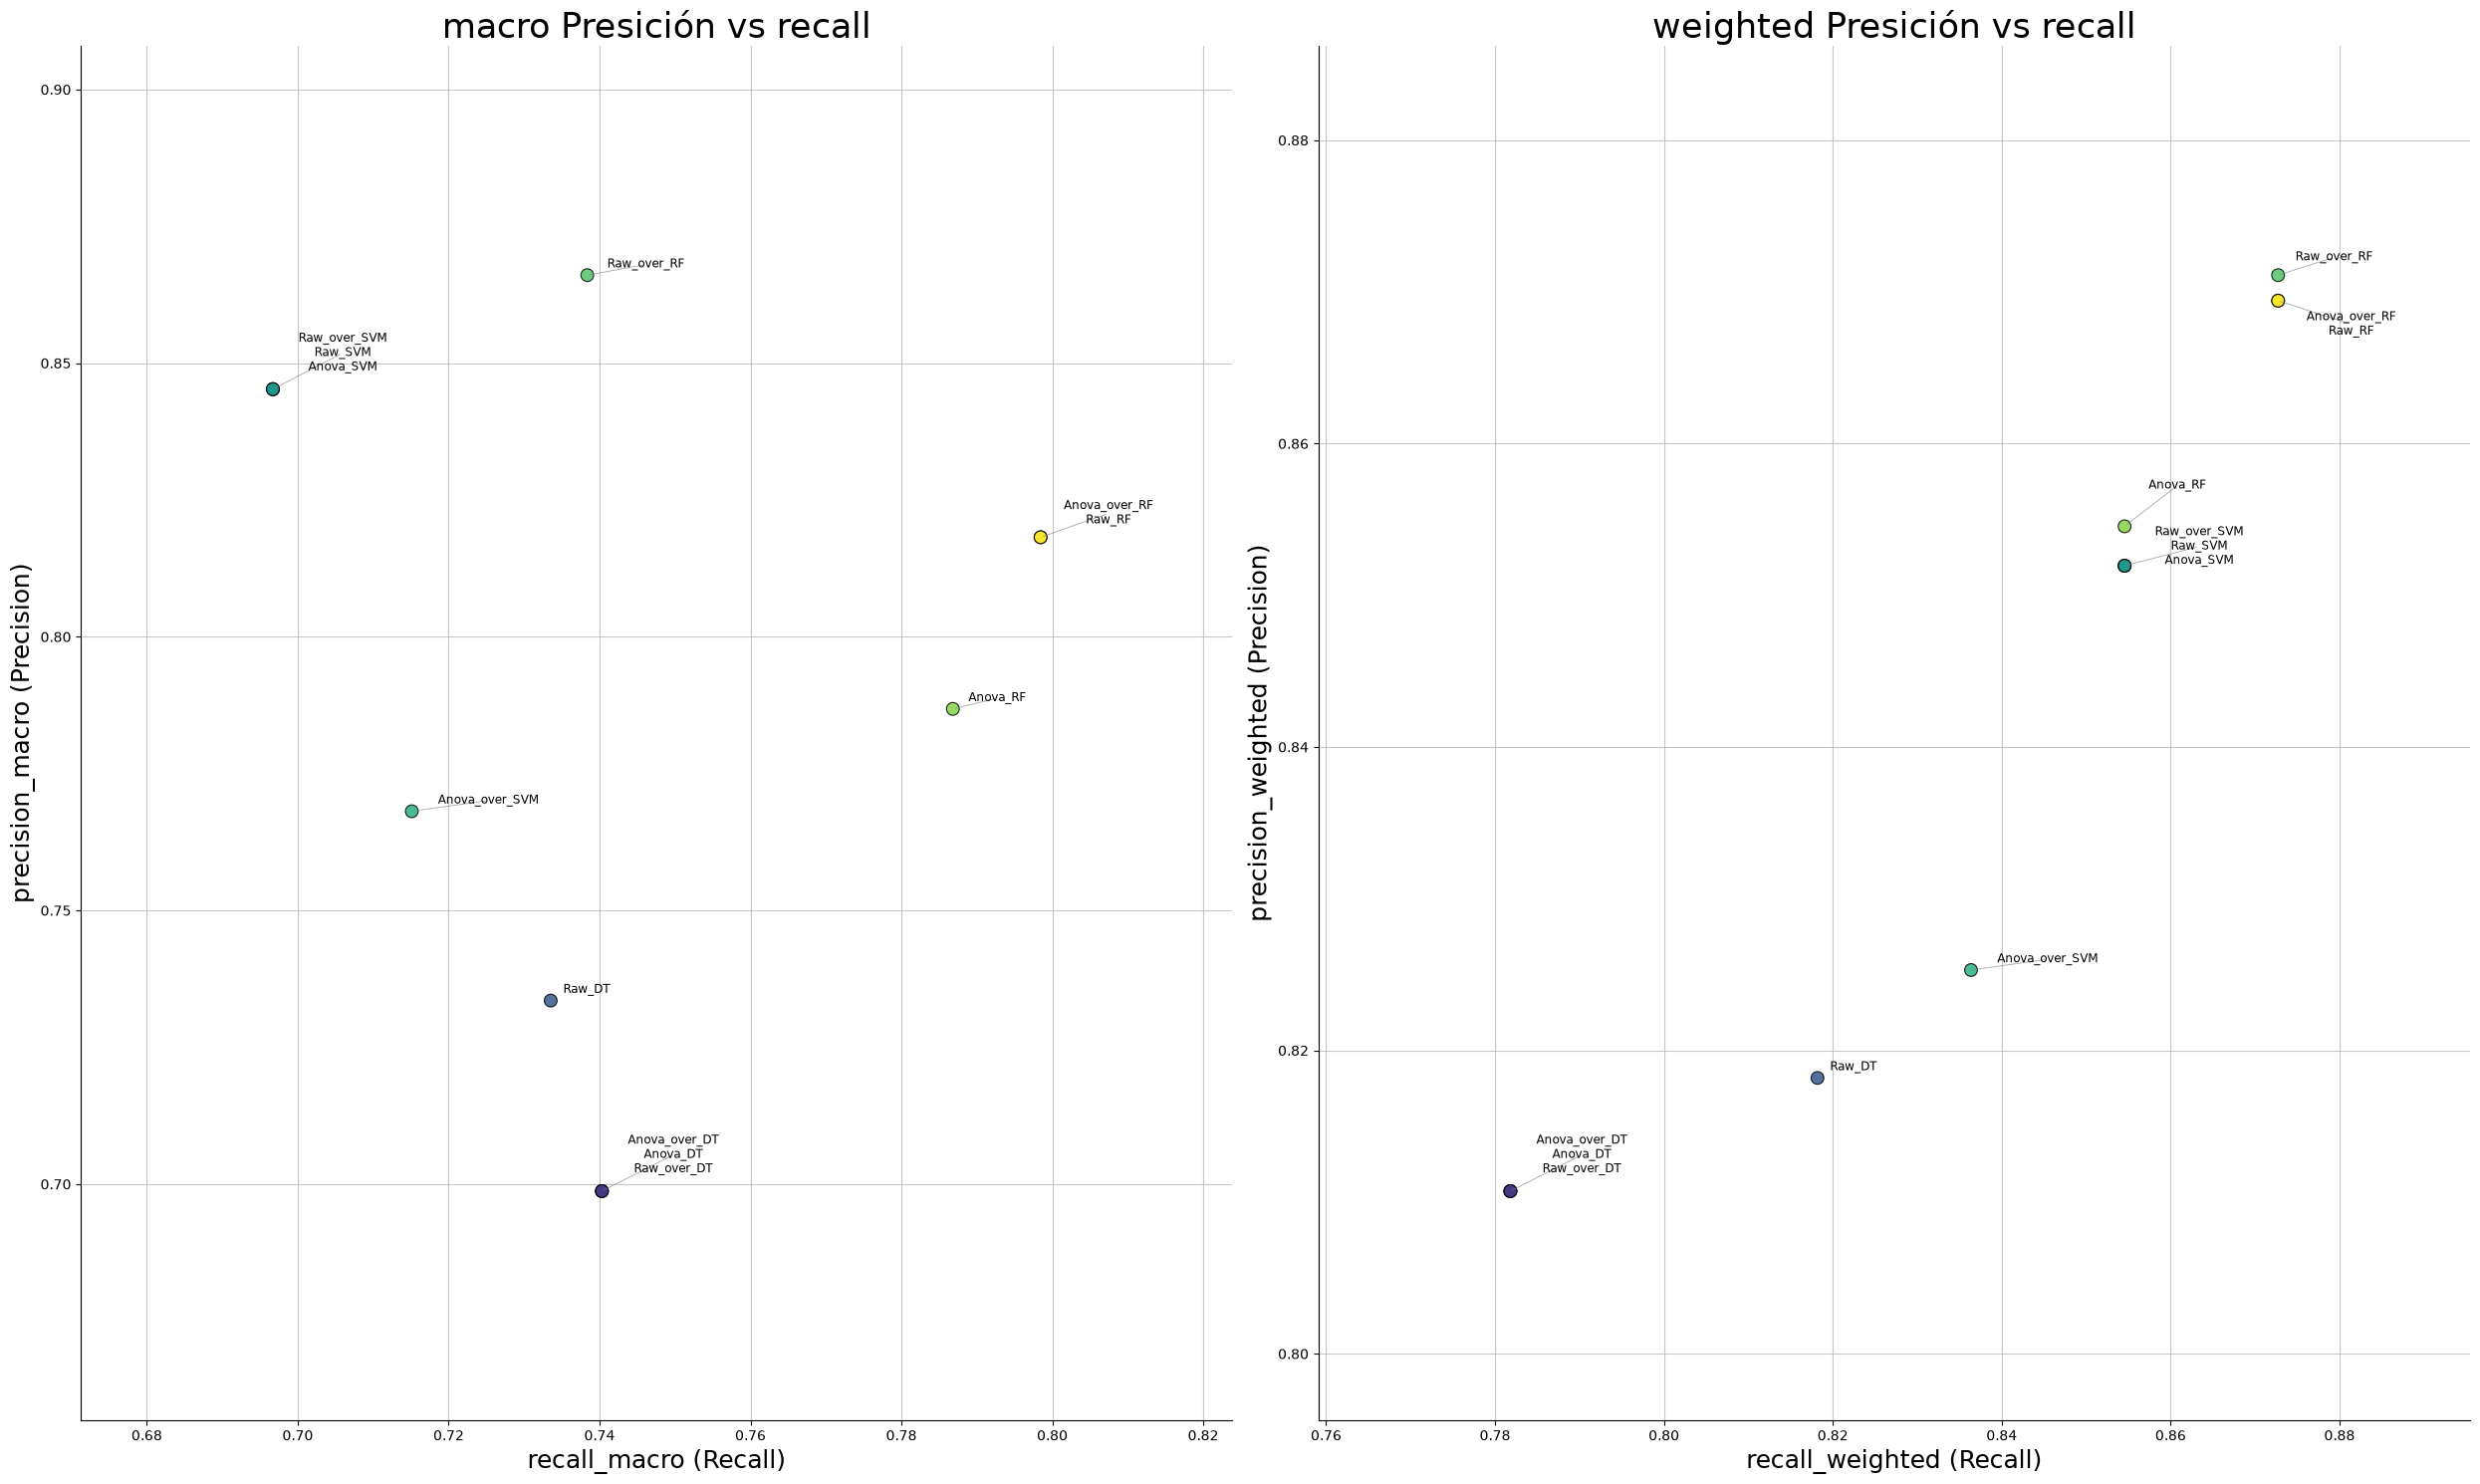

In [24]:
res_df=res_df.sort_values("F-1_score_macro")
res_colors=plt.cm.viridis(np.linspace(0, 1, len(res_df.index)))

bar_plot, axes_bar= plt.subplots(1,2, figsize=(20, 10))
scatter_plot, axes_scat= plt.subplots(1,2, figsize=(25, 15))
#bar plot of f1 macro
for i, metric in enumerate(["F-1_score_macro","F-1_score_weighted"]):
    axes_bar[i].bar(res_df.index, res_df[metric], color=res_colors, edgecolor="black")
    axes_bar[i].set_title(f"Bar plot of the results {metric}",fontsize=15)
    axes_bar[i].set_ylabel(metric, fontsize=15)
    axes_bar[i].tick_params(axis="x", rotation=45)
    axes_bar[i].set_xticks(range(len(res_df.index)))
    axes_bar[i].set_xticklabels(res_df.index, ha="right")

for i, metrics in enumerate([('precision_macro','recall_macro'),('precision_weighted', 'recall_weighted')]):
    x_vals = res_df[metrics[1]]
    y_vals = res_df[metrics[0]]

    x_min, x_max = x_vals.min(), x_vals.max()
    y_min, y_max = y_vals.min(), y_vals.max()
    x_pad = (x_max - x_min) * 0.25 if x_max > x_min else 0.05
    y_pad = (y_max - y_min) * 0.25 if y_max > y_min else 0.05

    xlims = (max(0, x_min - x_pad), min(1.02, x_max + x_pad))
    ylims = (max(0, y_min - y_pad), min(1.02, y_max + y_pad))
    axes_scat[i].scatter(
        res_df[metrics[1]],
        res_df[metrics[0]],
        c=res_colors,
        s=85,
        alpha=0.85,
        edgecolors='black',
        linewidths=0.8,
        zorder=3
    )

    grouped = (
    res_df.assign(
        x_round=res_df[metrics[1]].round(5),
        y_round=res_df[metrics[0]].round(5),
        label=res_df.index.astype(str)
    )
    .groupby(['x_round', 'y_round'], as_index=False)
    .agg({'label': '\n'.join, metrics[1]: 'first', metrics[0]: 'first'})
    )

    texts = [
        axes_scat[i].text(row[metrics[1]], row[metrics[0]], row['label'], fontsize=8.5, zorder=4)
        for _, row in grouped.iterrows()
    ]
    sufix=metrics[0].split("_")[1]
    axes_scat[i].set_title(f"{sufix} Presición vs recall", fontsize=25)
    axes_scat[i].set_xlabel(f"{metrics[1]} (Recall)", fontsize=18)
    axes_scat[i].set_ylabel(f"{metrics[0]} (Precision)", fontsize=18)
    axes_scat[i].set_xlim(xlims)
    axes_scat[i].set_ylim(ylims)
    axes_scat[i].grid(True, linestyle='-', alpha=0.7, zorder=0)
    axes_scat[i].spines['top'].set_visible(False)
    axes_scat[i].spines['right'].set_visible(False)
    adjust_text(
        texts,
        x=x_vals.values,
        y=y_vals.values,
        expand=(1.25, 1.4),
        force_text=(0.6, 1.2),
        ax=axes_scat[i],
        lim=1000,
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.6, alpha=0.7)
    )
    


plt.tight_layout()
bar_plot.savefig("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/F1_metrics_all_results_MLclassic.png", dpi=500)
scatter_plot.savefig("/export/space3/users/ismadlsh/LCG/S5/Machine_learning_algorithms_RE_state/results/ML_classic/Presición_recall_all_results_MLclassic.png", dpi=500)
plt.show()